In [1]:
import scanpy as sc
import os
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import numpy as np
import squidpy as sq
import pandas as pd
from scipy.stats import spearmanr
import seaborn as sns
import decoupler as dc
from scipy.spatial import cKDTree
from collections import defaultdict
import scicm
from Xenium_5K_IPF_constants import ALL_SUBTYPE_LIST, CMAP_COLORLIST, EPITHELIAL_SUBTYPE, WORK_PATH

# Option
sc.settings.verbosity = 3
plt.rcParams["font.family"] = "Fira Sans" 
%matplotlib ipympl

# Constant Declaration
dist_list = [20, 30, 40, 50]

/home/s_nakamura/test_env/lib/python3.12/site-packages/scicm/cm.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources as _pkg_resources


In [2]:

REV_PATH=f"{WORK_PATH}Revision/103/"
os.makedirs(REV_PATH, exist_ok=True)

In [3]:
epi_cptime = pd.read_csv(f"{WORK_PATH}CSV/021_epithelial_cPosition.csv", index_col="cell_id")

In [4]:
adata = sc.read_h5ad(f"{WORK_PATH}AnnData/spatial_merged.h5ad")
celltype = pd.read_csv(f"{WORK_PATH}CSV/013_merge_type.csv", index_col="cell_id")
adata = adata[celltype.index,].copy()
adata.obs = pd.merge(adata.obs, celltype[["cell_type_major", "subtype"]], left_index=True, right_index=True)

In [5]:
ne_adata = adata[~adata.obs["cell_type_major"].isin(["Epithelial"])].copy()
e_adata = adata[adata.obs["cell_type_major"].isin(["Epithelial"])].copy()

In [6]:
ne_coords = ne_adata.obsm["spatial"]
ne_ids  = ne_adata.obs_names

In [7]:
# Build a KD-tree on non-epithelial coordinates for fast radius queries
tree = cKDTree(ne_coords)

epi_ids = e_adata.obs_names.intersection(epi_cptime.index)

In [8]:
# Extract spatial coordinates once and create a mapping from obs_name to row index for fast lookup
name_to_row = {name: i for i, name in enumerate(adata.obs_names)}
coords = adata.obsm["spatial"]

epi_nei_dicts = {key:{} for key in dist_list}

In [9]:
for cid in epi_ids:
    target_coord = coords[name_to_row[cid]]

    # Indices returned here are relative to the non-epithelial subset
    
    idxs_list = [tree.query_ball_point(target_coord, r=dist) for dist in dist_list]

    for d, idxs in zip(dist_list, idxs_list):
        if len(idxs) == 0:
            epi_nei_dicts[d][cid] = {}
            continue

        # Compute distances only for neighbors within the radius (much cheaper than all-pairs distances)
        neigh_coords = ne_coords[idxs]
        dists = np.linalg.norm(neigh_coords - target_coord, axis=1)
    
        # Map non-epithelial indices to non-epithelial cell IDs and store distances
        epi_nei_dicts[d][cid] = {ne_ids[i]: float(d) for i, d in zip(idxs, dists)}

In [10]:
# Non-epithelial to epthelial continuum position and distances
ne_ids = set(ne_ids)
ne_nei_dicts = {d:defaultdict(dict) for d in dist_list}
for d, epi_nei_dict in epi_nei_dicts.items():
    for epi_id, neigh_dict in epi_nei_dict.items():
        for nbr_id, dd in neigh_dict.items():
            if nbr_id in ne_ids:
                ne_nei_dicts[d][nbr_id][epi_id] = float(dd)

for d in dist_list:
    ne_nei_dicts[d] = dict(ne_nei_dicts[d])

In [11]:
epi_t = epi_cptime["C_position"]  # index=cell_id, column "t"

out = {key:{} for key in dist_list}
atol = 1e-8  # tolerance for boundary equality

for d in dist_list:
    ne_nei_dict = ne_nei_dicts[d]
    for ne_id, epi_di in ne_nei_dict.items():
        e_ids = np.fromiter(epi_di.keys(), dtype=object)
        dists = np.fromiter(epi_di.values(), dtype=float)
        tvals = epi_t.reindex(e_ids).to_numpy(dtype=float)
    
        # Priority case: if any neighbor is exactly on the boundary (d == dist),
        # use its t value and ignore all others.
        on_boundary = np.isclose(dists, d, atol=atol)
        if np.any(on_boundary):
            boundary_idx = np.where(on_boundary)[0][0]  # assume at most one
            out[d][ne_id] = float(tvals[boundary_idx])
            continue
    
        # Otherwise, use neighbors strictly inside the radius with linear weights w = dist - d
        w = d - dists  # >0 because d<dist here
        w_norm = w / w.sum()  # normalized so sum(w_norm)=1
        out[d][ne_id] = float((tvals * w_norm).sum())

    ne_cptime = pd.Series(out[d], name=f"{d}_Cpos")
    ne_cptime.index.name = "cell_id"
    
    ne_adata.obs[f"{d}_Cpos"]=ne_cptime
    ne_adata.obs[f"{d}_Cpos_nan"]=np.where(ne_adata.obs[f"{d}_Cpos"].isna(), "undefined", "defined")

In [12]:
progeny = dc.op.progeny(organism="human")

In [13]:
score_list = {d:{} for d in dist_list}
for d in dist_list:
    ne_cp_df = ne_adata[ne_adata.obs[f"{d}_Cpos_nan"]=="defined"].obs[[f"{d}_Cpos"]].copy()
    ne_cp_df.rename(columns={f"{d}_Cpos": "C_position"}, inplace=True)
    cp_df = pd.concat([epi_cptime[["C_position"]], ne_cp_df], axis=0)
    cp_adata = adata[cp_df.index, ].copy()
    cp_adata.obs["C_position"]=cp_df[["C_position"]]
    cp_adata.raw = cp_adata.copy()
    sc.pp.normalize_total(cp_adata, target_sum=1e4)
    sc.pp.log1p(cp_adata)
    dc.mt.mlm(data=cp_adata, net=progeny)
    score_list[d]=dc.pp.get_obsm(adata=cp_adata, key="score_mlm")

normalizing counts per cell
    finished (0:00:01)
normalizing counts per cell
    finished (0:00:00)
normalizing counts per cell
    finished (0:00:00)
normalizing counts per cell
    finished (0:00:00)


In [22]:
ct_list = ['Epithelial', 'Endothelial', 'NK/T cell', 'Fibroblast', 'Dendritic cell',
           'B/Plasma cell', 'Granulocyte', 'SMC/Pericyte', 'Monocyte/MΦ', 'TLS-associated']

pathways = ["Androgen"]

In [23]:
n_bins = 20

bin_pws_dict = {
    d:{
        key: pd.DataFrame(0.0, index=[n for n in range(n_bins)], columns=ct_list) 
        for key in pathways
    } 
    for d in dist_list
}

for d in dist_list:
    for m_type in ct_list:
        bin_temp= dc.pp.bin_order(
            adata=score_list[d][score_list[d].obs["cell_type_major"]==m_type].copy(),
            order="C_position",
            names=pathways,
            label="C_position",
            nbins=n_bins
        )
    
        
        out = (
            bin_temp.groupby(["name", "order"], as_index=False)
              .agg(value_mean=("value", "mean"))
              .sort_values(["name", "order"])
        )
        
        for pw in pathways:
            bin_pws_dict[d][pw].loc[:,m_type] = list(out[out["name"]==pw]["value_mean"])


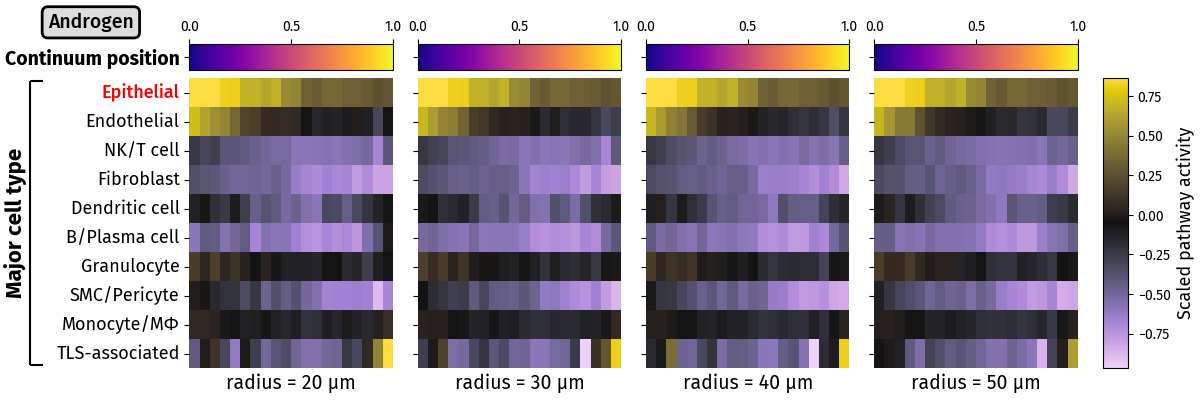

In [24]:
for pway in pathways:
    
    fig, axes = plt.subplots(2,6,figsize=(12,4), height_ratios=(1,11),width_ratios=(6,8,8,8,8,1))
    axes = axes.flatten()
    fig.subplots_adjust(left=0.01, right=0.94, top=0.89, bottom=0.08, hspace=0.05, wspace=0.15)

    axes[0].axis("off")
    axes[5].axis("off")

    # Continuum position bar
    norm_cp = matplotlib.colors.Normalize(vmin=0, vmax=1)
    sm_cp = plt.cm.ScalarMappable(cmap="plasma", norm=norm_cp)
    for ax in axes[1:5]:
        cp_bar = fig.colorbar(sm_cp, cax=ax, ticks=[0, 0.5, 1], orientation="horizontal")
        cp_bar.ax.set_xticklabels(['0.0', "0.5", "1.0"], fontsize=10, c="black")
        ax.xaxis.set_ticks_position('top')
        ax.set_yticks([0.5], [""])
    axes[1].set_yticklabels(["Continuum position"], fontsize=14, weight="bold")

    v_max = bin_pws_dict[dist_list[0]][pway].max().max()
    v_min = bin_pws_dict[dist_list[1]][pway].min().min()
    for d in dist_list[1:]:
        v_max = max(v_max, bin_pws_dict[d][pway].max().max())
        v_min = min(v_min, bin_pws_dict[d][pway].min().min())
    cl = (v_max-v_min)*0.1
    vmax, vmin = v_max-cl, v_min+cl

    for d, ax in zip(dist_list, axes[7:11]):
        sns.heatmap(bin_pws_dict[d][pway].T, ax=ax,  cmap='scicm.PkY', cbar=None, vmax=vmax, vmin=vmin)
        # ax_box = axes[1].get_position()
    
        # delete X-axis labels
        ax.set_xlabel(f"radius = {d} µm", fontsize=14)
        ax.set_xticks([])
        if d != dist_list[0]:
            ax.set_yticks(ax.get_yticks(), [])
    axes[7].tick_params("y", labelsize=13)
    for n, t in enumerate(axes[7].get_yticklabels()):
        if n == 0:
            t.set(color="red", weight=500)
    
    # activity score bar
    norm_cb = matplotlib.colors.Normalize(vmin=vmin, vmax=vmax)
    sm_cb = plt.cm.ScalarMappable(cmap="scicm.PkY", norm=norm_cb)
    cbar = fig.colorbar(sm_cb, cax=axes[-1], orientation="vertical")
    axes[-1].set_ylabel("Scaled pathway activity", fontsize=13)
    axes[-1].tick_params("y", labelsize=10)
    
    # y-axis labels
    axes[6].set_xlim(0,5)
    axes[6].set_ylim(0,1)
    axes[6].axis("off")
    axes[6].vlines(x=0.6, ymin=0.01, ymax=0.99, color="black")
    axes[6].hlines(y=0.01, xmin=0.6, xmax=1, color="black")
    axes[6].hlines(y=0.99, xmin=0.6, xmax=1, color="black")
    axes[6].text(s=f"Major cell type", x=0.5, y=0.5, fontsize=16, ha="right", va="center", rotation=90, weight="bold")

    boxdic = {
        "facecolor" : "#dddddd",
        "edgecolor" : "black",
        "boxstyle" : "Round",
        "linewidth" : 2
    }
    fig.text(x=0.04, y=0.93, s=f"{pway}", fontsize=14, weight=500, bbox=boxdic, ha="left")
    plt.savefig(f"{REV_PATH}103_exEcNP_cPosition_projeny_mat_{pway}_each_radius.png", dpi=500, format="png", bbox_inches=None)

In [25]:
records = []

for pway in pathways:
    for d in dist_list:

        mat = bin_pws_dict[d][pway].T.copy()

        mat.index.name = "Major_cell_type"
        mat.columns.name = "Continuum_bin"

        # Long format
        df_temp = (
            mat
            .stack(dropna=False)
            .rename("Scaled_pathway_activity")
            .reset_index()
        )

        df_temp.insert(0, "Pathway", pway)
        df_temp.insert(1, "Radius_um", d)

        records.append(df_temp)

df_source = pd.concat(records, ignore_index=True)

df_source.to_csv(f"{REV_PATH}103_exEcNP_cPosition_projeny_mat_{pway}_each_radius_source_data.csv", index=True)

/tmp/ipykernel_4293/3903648329.py:14: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  .stack(dropna=False)
/tmp/ipykernel_4293/3903648329.py:14: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  .stack(dropna=False)
/tmp/ipykernel_4293/3903648329.py:14: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  .stack(dropna=False)
/tmp/ipykernel_4293/3903648329.py:14: FutureWarni